---
# Lab Experiment - 6
---
### Analysis and Visualization of COVID-19 Dataset using Python
---
### Name: Chidroop M J
### Registered number: 212225240029
---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/mjchidroop/plotting_final/main/covid_case.csv"
data = pd.read_csv(url)

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [2]:
print("First 5 rows:")
print(data.head())

print("\nDataset Shape:")
print(data.shape)

print("\nColumn Names:")
print(data.columns)

print("\nMissing Values:")
print(data.isnull().sum())

data = data.dropna()
data['Date'] = pd.to_datetime(data['Date'])

print("\nTotal Records:", len(data))

print("\nStatistical Summary:")
print(data.describe())

First 5 rows:
         Date Country  Confirmed  Deaths  Recovered  Active
0  2022-05-10   Japan     111268    2216      84123   24929
1  2020-11-26   Japan     913756   18300     774705  120751
2  2022-02-08   Japan     719315   20474     431785  267056
3  2022-08-13      UK     215176    2712     168625   43839
4  2022-01-17   Italy     918040   16634     679304  222102

Dataset Shape:
(1200, 6)

Column Names:
Index(['Date', 'Country', 'Confirmed', 'Deaths', 'Recovered', 'Active'], dtype='object')

Missing Values:
Date         0
Country      0
Confirmed    0
Deaths       0
Recovered    0
Active       0
dtype: int64

Total Records: 1200

Statistical Summary:
                      Date      Confirmed        Deaths      Recovered  \
count                 1200    1200.000000   1200.000000    1200.000000   
mean   2021-07-08 05:15:36  510035.990000   8778.575000  394193.676667   
min    2020-01-01 00:00:00    1215.000000      8.000000     831.000000   
25%    2020-10-20 00:00:00  263086.50

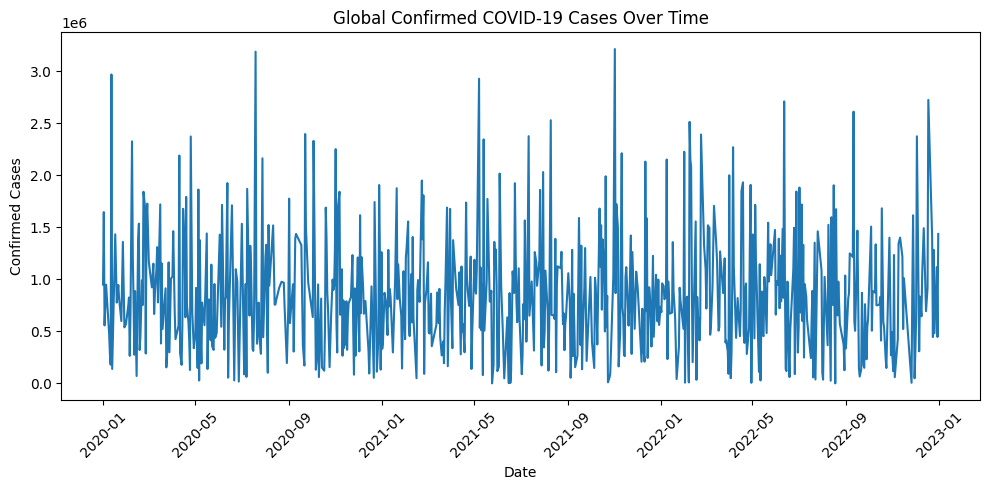

In [3]:
global_cases = data.groupby('Date')['Confirmed'].sum()

plt.figure(figsize=(10, 5))
plt.plot(global_cases.index, global_cases.values, color='tab:blue')
plt.title("Global Confirmed COVID-19 Cases Over Time")
plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

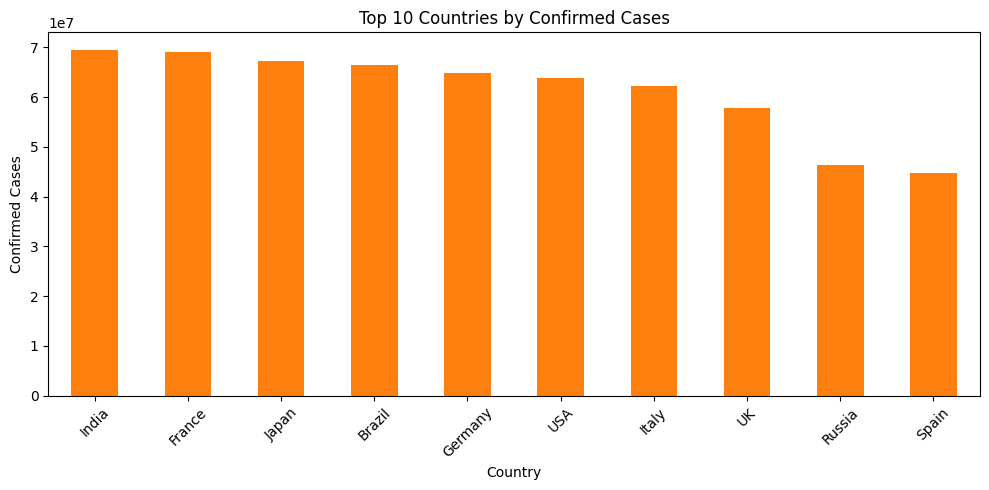

In [4]:
top10 = data.groupby('Country')['Confirmed'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
top10.plot(kind='bar', color='tab:orange')
plt.title("Top 10 Countries by Confirmed Cases")
plt.xlabel("Country")
plt.ylabel("Confirmed Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

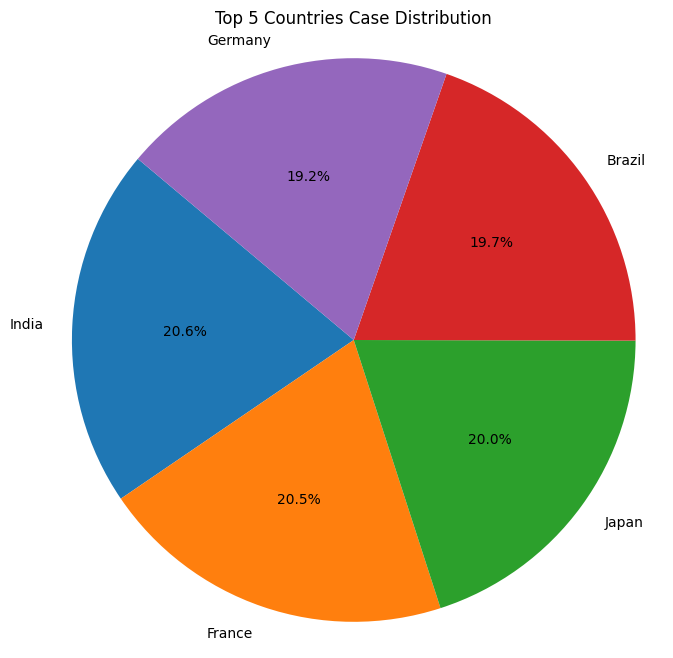

In [5]:
top5 = data.groupby('Country')['Confirmed'].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(8, 8))
plt.pie(top5, labels=top5.index, autopct='%1.1f%%', startangle=140)
plt.title("Top 5 Countries Case Distribution")
plt.axis('equal')
plt.show()

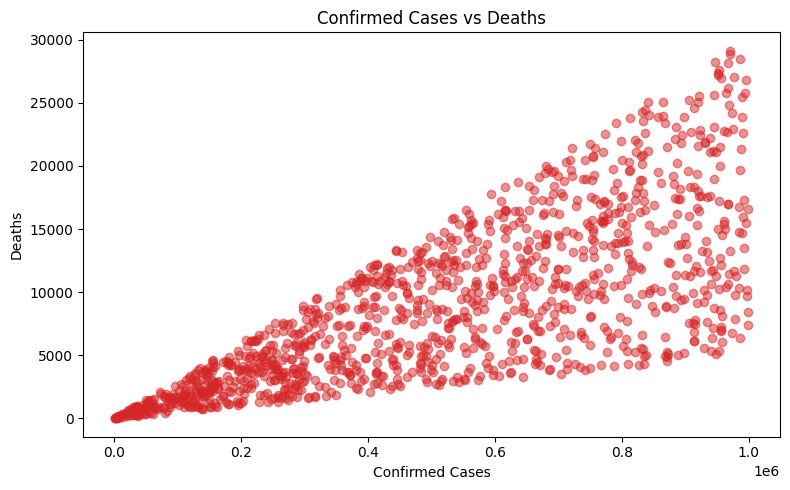

In [6]:
plt.figure(figsize=(8, 5))
plt.scatter(data['Confirmed'], data['Deaths'], alpha=0.5, color='tab:red')
plt.title("Confirmed Cases vs Deaths")
plt.xlabel("Confirmed Cases")
plt.ylabel("Deaths")
plt.tight_layout()
plt.show()

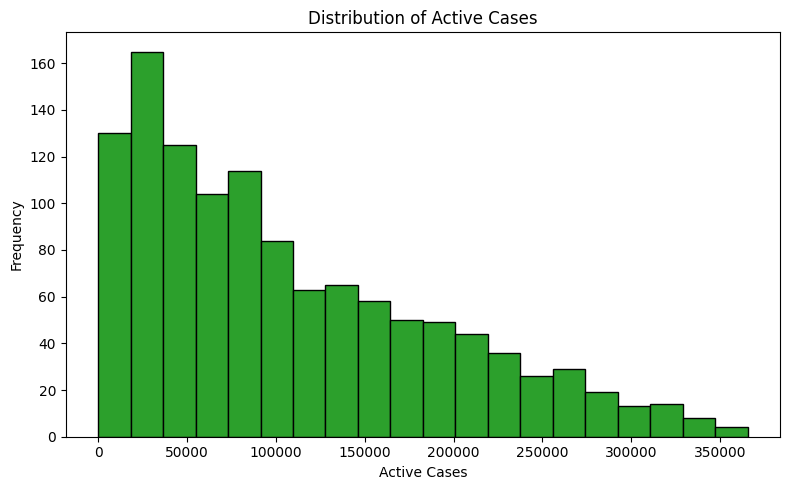

In [7]:
plt.figure(figsize=(8, 5))
plt.hist(data['Active'], bins=20, color='tab:green', edgecolor='black')
plt.title("Distribution of Active Cases")
plt.xlabel("Active Cases")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

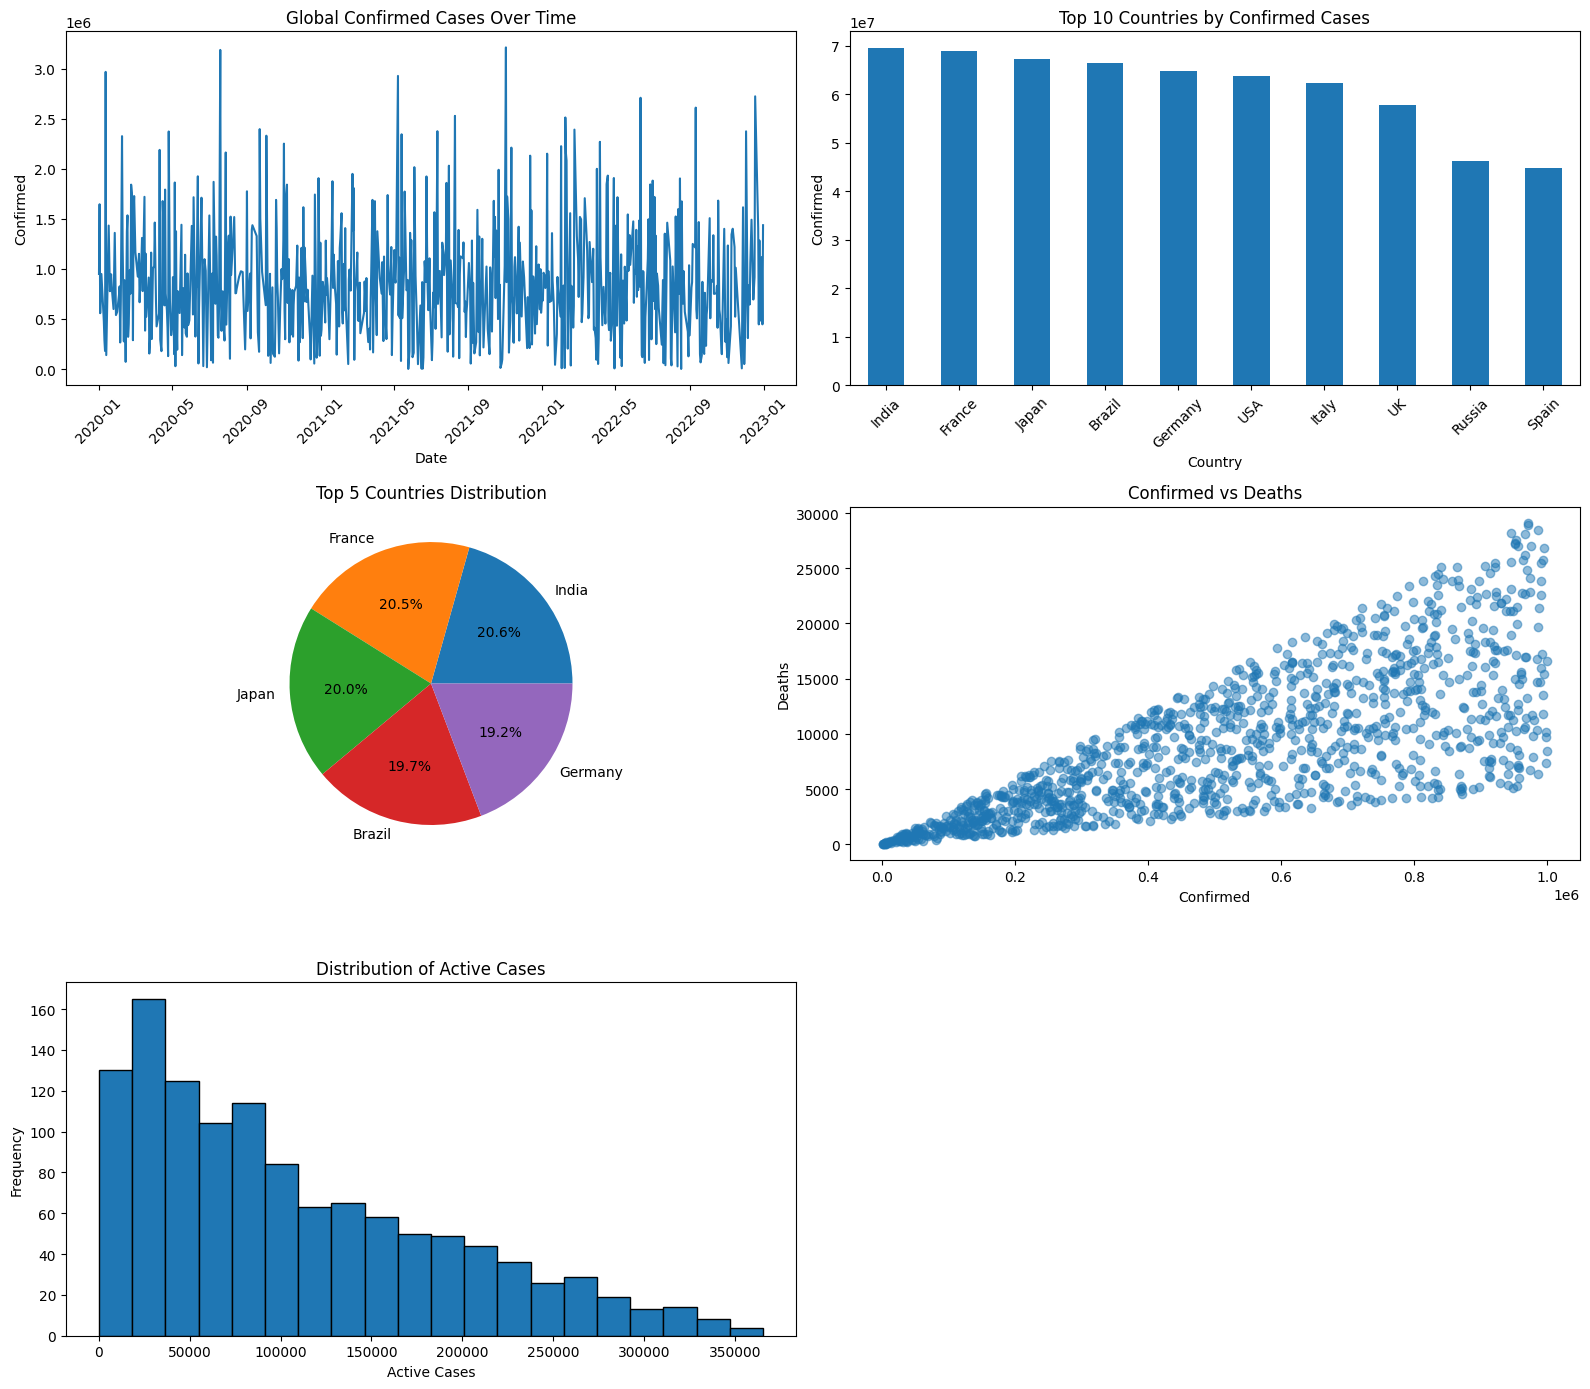

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
axes = axes.flatten()

axes[0].plot(global_cases.index, global_cases.values)
axes[0].set_title("Global Confirmed Cases Over Time")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Confirmed")
axes[0].tick_params(axis='x', rotation=45)

top10.plot(kind='bar', ax=axes[1])
axes[1].set_title("Top 10 Countries by Confirmed Cases")
axes[1].set_xlabel("Country")
axes[1].set_ylabel("Confirmed")
axes[1].tick_params(axis='x', rotation=45)

axes[2].pie(top5, labels=top5.index, autopct='%1.1f%%')
axes[2].set_title("Top 5 Countries Distribution")

axes[3].scatter(data['Confirmed'], data['Deaths'], alpha=0.5)
axes[3].set_title("Confirmed vs Deaths")
axes[3].set_xlabel("Confirmed")
axes[3].set_ylabel("Deaths")

axes[4].hist(data['Active'], bins=20, edgecolor='black')
axes[4].set_title("Distribution of Active Cases")
axes[4].set_xlabel("Active Cases")
axes[4].set_ylabel("Frequency")

axes[5].axis('off')
plt.tight_layout()
plt.show()

In [9]:
print("Total records analysed:", len(data))
print("Number of countries:", data['Country'].nunique())
print("Date range:", data['Date'].min().date(), "to", data['Date'].max().date())
print("Top 5 countries by confirmed cases:")
print(top5)

Total records analysed: 1200
Number of countries: 10
Date range: 2020-01-01 to 2022-12-31
Top 5 countries by confirmed cases:
Country
India      69549474
France     68982578
Japan      67361162
Brazil     66395679
Germany    64823710
Name: Confirmed, dtype: int64
